In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [28]:
DATA_PATH = Path("../data/raw/car data.csv")

df = pd.read_csv(DATA_PATH)

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [29]:
df.shape


(301, 9)

In [30]:
df.columns.tolist()

['Car_Name',
 'Year',
 'Selling_Price',
 'Present_Price',
 'Kms_Driven',
 'Fuel_Type',
 'Seller_Type',
 'Transmission',
 'Owner']

In [31]:
df.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [32]:
df.dtypes

Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [34]:
df.describe(include="all")

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
count,301,301.000000,301.000000,301.000000,301.000000,301,301,301,301.000000
unique,98,NaN,NaN,NaN,NaN,3,2,2,NaN
top,city,NaN,NaN,NaN,NaN,Petrol,Dealer,Manual,NaN
freq,26,NaN,NaN,NaN,NaN,239,195,261,NaN
mean,NaN,2013.627907,4.661296,7.628472,36947.205980,NaN,NaN,NaN,0.043189
std,NaN,2.891554,5.082812,8.644115,38886.883882,NaN,NaN,NaN,0.247915
min,NaN,2003.000000,0.100000,0.320000,500.000000,NaN,NaN,NaN,0.000000
25%,NaN,2012.000000,0.900000,1.200000,15000.000000,NaN,NaN,NaN,0.000000
50%,NaN,2014.000000,3.600000,6.400000,32000.000000,NaN,NaN,NaN,0.000000
75%,NaN,2016.000000,6.000000,9.900000,48767.000000,NaN,NaN,NaN,0.000000


In [35]:
df.duplicated().sum()

np.int64(2)

In [36]:
print("Prices <= 0:", (df["Selling_Price"] <= 0).sum())
print("Negative mileage:", (df["Kms_Driven"] < 0).sum())
print("Invalid years:", ((df["Year"] < 1950) | (df["Year"] > 2026)).sum())

Prices <= 0: 0
Negative mileage: 0
Invalid years: 0


In [37]:
from pathlib import Path

FIGURES_PATH = Path("../reports/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

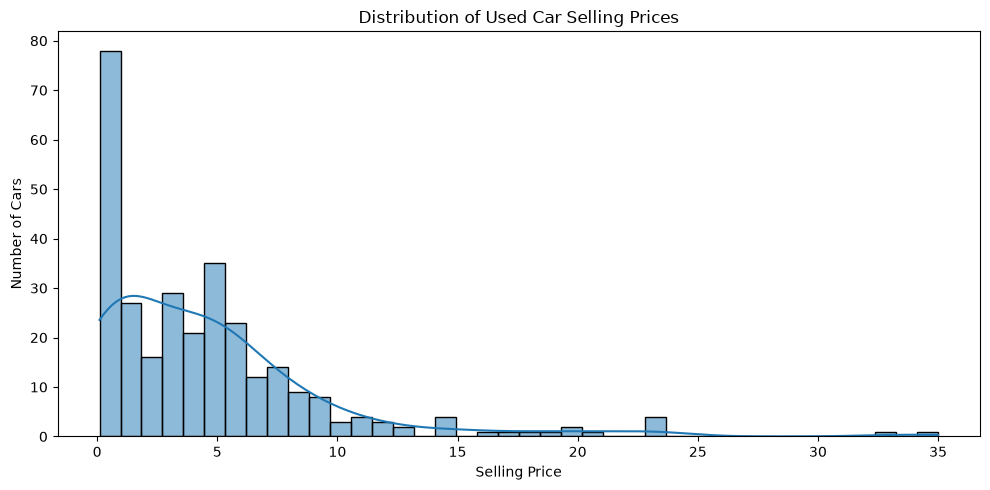

In [38]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Selling_Price", bins=40, kde=True)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.savefig(FIGURES_PATH / "01_price_distribution.png", dpi=300)
plt.show()

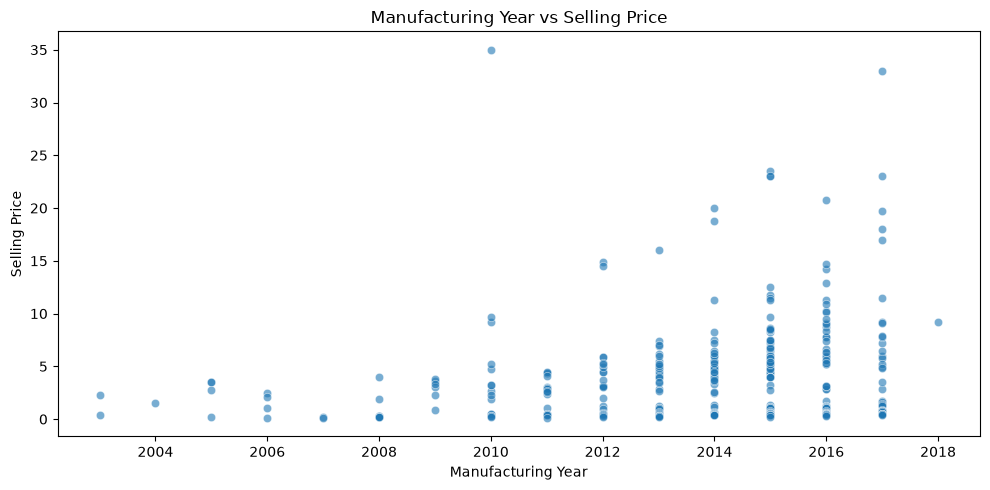

In [39]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x="Year", y="Selling_Price", alpha=0.6)

plt.title("Manufacturing Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.savefig(FIGURES_PATH / "02_year_vs_price.png", dpi=300)
plt.show()

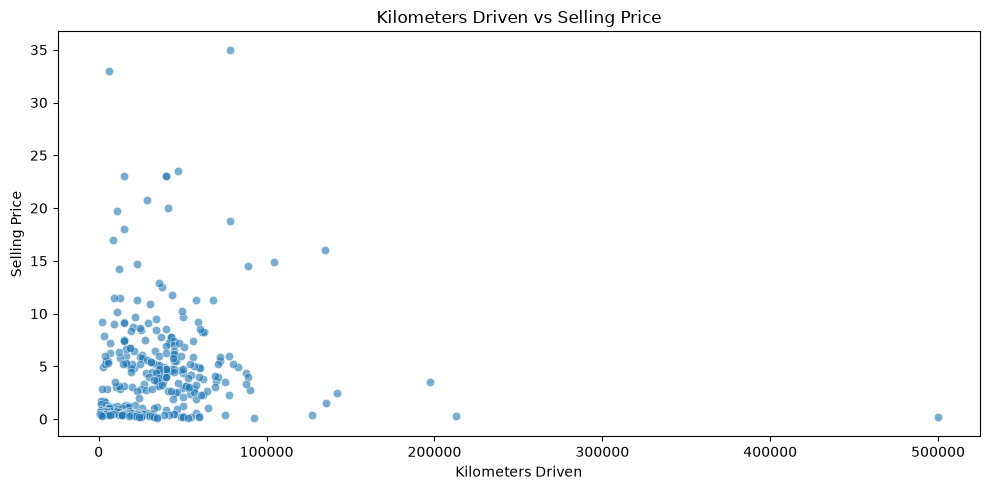

In [40]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x="Kms_Driven", y="Selling_Price", alpha=0.6)

plt.title("Kilometers Driven vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.savefig(FIGURES_PATH / "03_km_driven_vs_price.png", dpi=300)
plt.show()

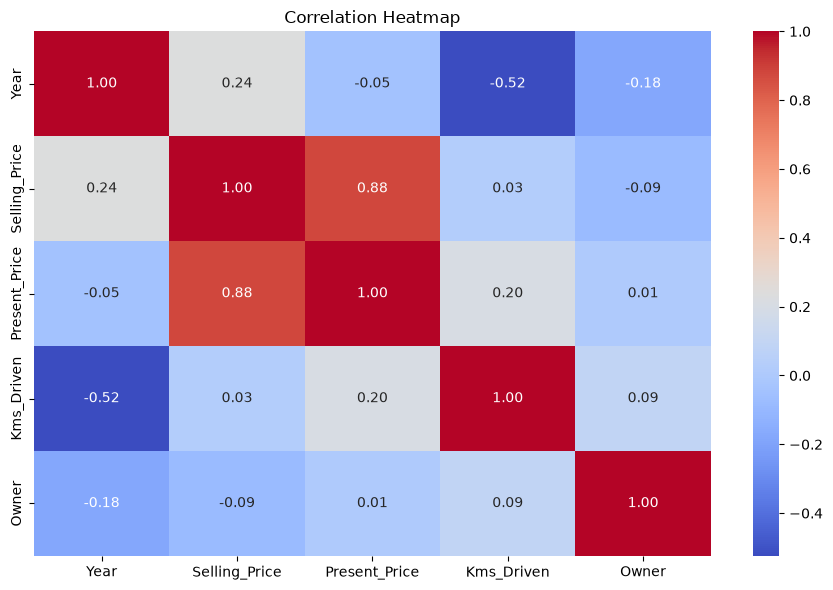

In [41]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))

sns.heatmap(
    numeric_df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "04_correlation_heatmap.png", dpi=300)
plt.show()

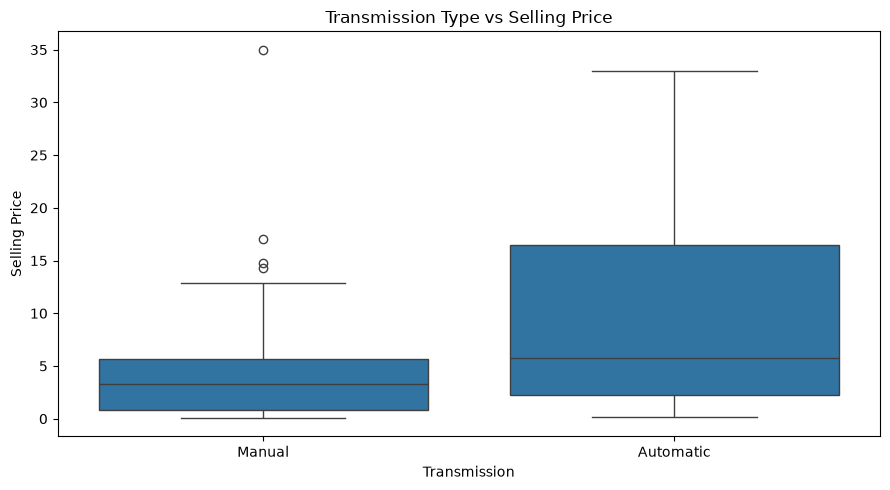

In [42]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Transmission", y="Selling_Price")

plt.title("Transmission Type vs Selling Price")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.savefig(FIGURES_PATH / "05_transmission_vs_price.png", dpi=300)
plt.show()

In [43]:
correlations = df.select_dtypes(include="number").corr(numeric_only=True)

price_correlations = correlations["Selling_Price"].drop("Selling_Price")

price_correlations.reindex(
    price_correlations.abs().sort_values(ascending=False).index
)

Present_Price    0.878983
Year             0.236141
Owner           -0.088344
Kms_Driven       0.029187
Name: Selling_Price, dtype: float64

In [44]:
list(FIGURES_PATH.glob("*.png"))

[WindowsPath('../reports/figures/01_price_distribution.png'),
 WindowsPath('../reports/figures/02_year_vs_price.png'),
 WindowsPath('../reports/figures/03_km_driven_vs_price.png'),
 WindowsPath('../reports/figures/04_correlation_heatmap.png'),
 WindowsPath('../reports/figures/05_transmission_vs_price.png')]